In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# Tips 데이터 시각화 진행

*   hist() 히스토그램 그래프 표현
*   특정 데이터가 어느 구간에 많이 모여 있는지 파악



In [ ]:
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


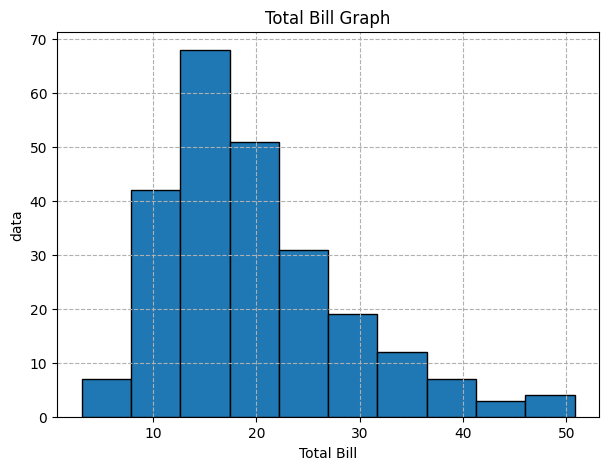

In [ ]:
# "총 결제 금액(total_bill)은 어느 구간에 가장 많이 분포할까?"

plt.figure(figsize = (7, 5))
plt.hist(tips['total_bill'], bins = 10, edgecolor = 'black')
#   x축을 total_bill로 설정
#   막대의 개수를 10개로 설정 (ex) 데이터 범위 :: 5달러 ~ 55달러  -> 이 영역을 균등하게 10개로 분할
#   막대의 경계선을 검정으로 설정
plt.title('Total Bill Graph')
plt.xlabel('Total Bill')
plt.ylabel('data')
plt.grid(linestyle = '--')
plt.show()

# (ex)
# 2달러~7달러 데이터 개수 :: 8
# 7달러~13달러 데이터 개수 :: 41
# 13달러~18달러 데이터 개수 :: 68
# 18달러~23달러 데이터 개수 :: 51
# ...

# 10 ~ 20달러 데이터가 가장 많이 분포
#   => 총 결제 금액은 주로 10~20달러 구간에 분포해있다.

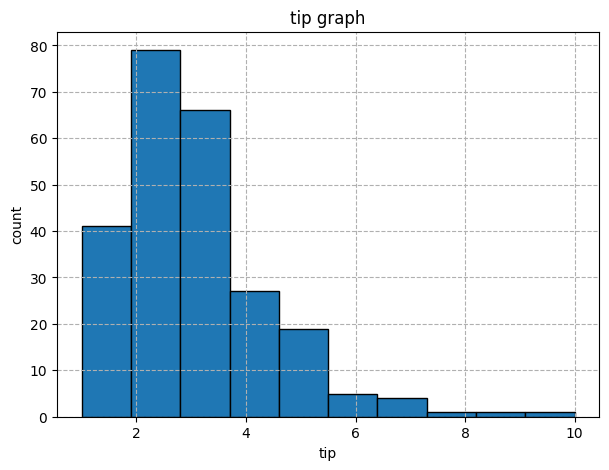

In [ ]:
# [문제] 팁 금액은 어느 구간에 가장 많이 분포할까?

# 히스토그램 그래프 출력
plt.figure(figsize = (7, 5))
plt.hist(tips['tip'], bins = 10, edgecolor = 'black')
plt.xlabel('tip')
plt.ylabel('count')
plt.title('tip graph')
plt.grid(linestyle='--')
plt.show()

# 해답 알아보기
#   => 2~4달러 구간에 많이 분포해있음

# Tips 데이터 시각화 진행


*   bar() 막대 그래프 표현
*   값을 비교하고 차이 확인에 활용



   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
day
Thur    17.682742
Fri     17.151579
Sat     20.441379
Sun     21.410000
Name: total_bill, dtype: float64


/tmp/ipykernel_1159/4189637544.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_bill = tips.groupby('day')['total_bill'].mean()   # '요일'별로 그룹짓기 -> 총 결제 금액 평균 내기


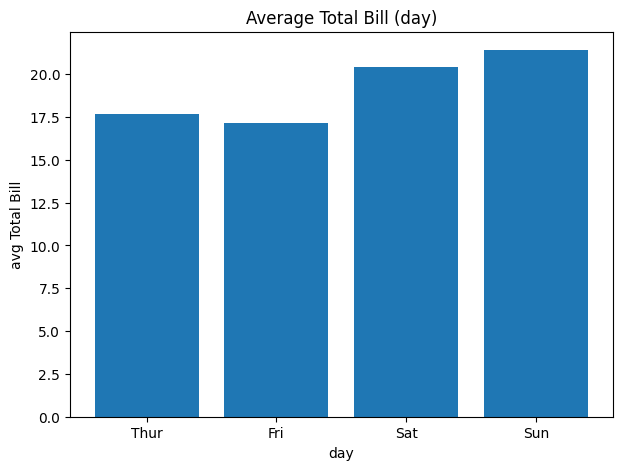

In [ ]:
# "요일(day)별 평균 결제 금액(total_bill)이 어떻게 다를까?"
print(tips.head())

# 그래프 표현 (요일별 결제 금액의 평균 구하기)
plt.figure(figsize = (7, 5))
avg_bill = tips.groupby('day')['total_bill'].mean()   # '요일'별로 그룹짓기 -> 총 결제 금액 평균 내기
  # avg_bill의 내용
  # 'thur' -> [total_bill] 7.56, 10.34, 13.00, ...    => 17.5
  # 'fri'  -> [total_bill] 40.17, 27.28, 12.03, ...   => 17.4
  # 'sat' -> [total_bill] 15.77, 39.42, 19.82, ...    => 20.0
  # 'sun' -> [total_bill] 16.99, 10.34, 21.01, ...    => 22.5
print(avg_bill)

plt.bar(avg_bill.index, avg_bill.values)
  # index :: 'Thur', 'Fri', 'Sat', 'Sun'    -> x축(가로축)
  # values :: 17.5, 17.4, 20.0, 22.5        -> y축(세로축)
plt.title('Average Total Bill (day)')
plt.xlabel('day')
plt.ylabel('avg Total Bill')
plt.show()

     total_bill   tip     sex smoker   day    time  size
0         16.99  1.01  Female     No   Sun  Dinner     2
1         10.34  1.66    Male     No   Sun  Dinner     3
2         21.01  3.50    Male     No   Sun  Dinner     3
3         23.68  3.31    Male     No   Sun  Dinner     2
4         24.59  3.61  Female     No   Sun  Dinner     4
..          ...   ...     ...    ...   ...     ...   ...
195        7.56  1.44    Male     No  Thur   Lunch     2
196       10.34  2.00    Male    Yes  Thur   Lunch     2
197       43.11  5.00  Female    Yes  Thur   Lunch     4
198       13.00  2.00  Female    Yes  Thur   Lunch     2
199       13.51  2.00    Male    Yes  Thur   Lunch     2

[200 rows x 7 columns]
time
Lunch     2.728088
Dinner    3.102670
Name: tip, dtype: float64


/tmp/ipykernel_1159/2209175921.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_tip = tips.groupby('time')['tip'].mean()


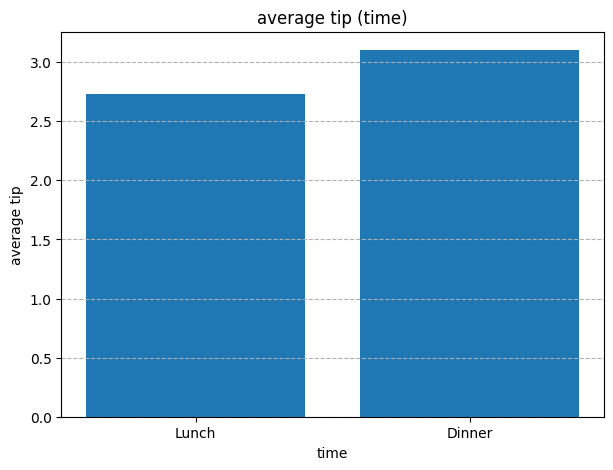

In [ ]:
# [문제] "점심과 저녁(time)의 "평균" 팁 금액(tip)은 어떻게 다를까?"
print(tips.head(200))

# 막대그래프 출력
plt.figure(figsize = (7, 5))
avg_tip = tips.groupby('time')['tip'].mean()
#  avg_tip 내용
#   'lunch' : (tip) 1.44, 2.0, 5.0, ...   => (평균)
#   'dinner' : (tip) 1.01, 1.66, 3.5, ... => (평균)
print(avg_tip)
plt.bar(avg_tip.index, avg_tip.values)    # (각 막대의 이름, 막대의 길이)
plt.title('average tip (time)')
plt.xlabel('time')
plt.ylabel('average tip')
plt.grid(axis = 'y', linestyle='--')    # y값들에 대한 눈금 표시
plt.show()

# 해답 확인
#   => 점심보다는 저녁의 팁 금액이 다소 높다.

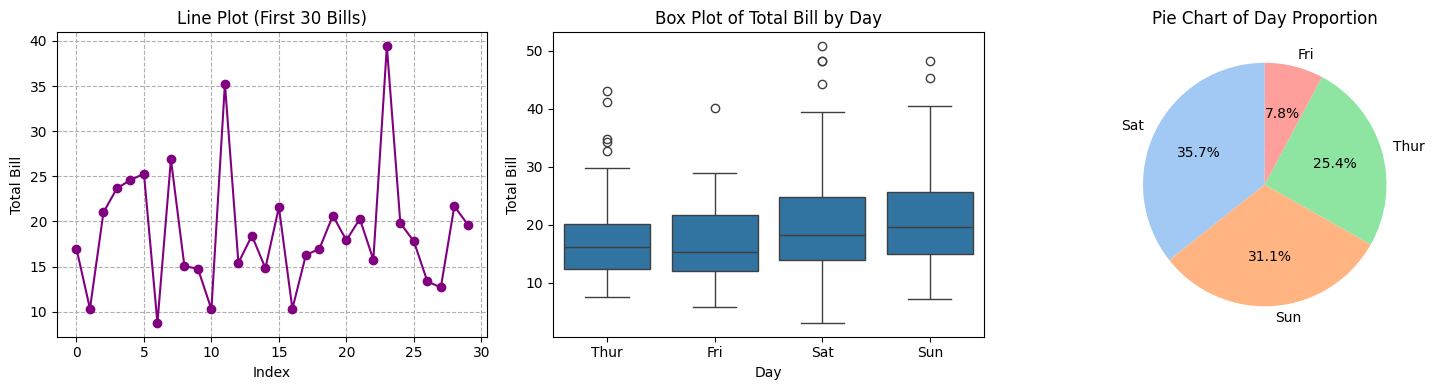